# Clasificador de género muscial

Objetivo: Lograr crear un clasificador de género musical. 

Estoy utilizando de base la metodología explicada por Ahmed, et.al. en "Musical genre classification using advanced audio analysis and deep learning techniques" (2024).

Criterios de éxito
1. Identificar correctamente los fragmentos de cación del dataset con su género (Validación y Pruebas)
1. Poder identificar el género de la canción completa
1. Poder determinar diferentes segmentos de la canción con su género asociado (estilo bounding box pero en música, de manera que una canción pueda pertenecer a múltiples géneros a la vez)
1. Relación de música por similitud. 

## Artículo base

Este aborda la teoría y diferentes estrategias para la clasificación de música, citando a diferentes autores con sus estrategias para este problema, y resultados. Entre ellos explica arquitecturas de Feed forward neural network (FNN), modelos de convolusión (CNN), modelos de convolusión modificados (Modified CNN), Recurrent Neural Network(RNN-LSTM), Support Vector Machine (SVM), K Nearest Neighbors (KNN) y compara sus resultados. 

En estos muestra qu la red modificaa CNN fue la que mejor resultados tuvo con una exactitud del 92.7%, seguida de la CNN regular con 85.56% y en ultimo lugar KNN con 70%.

## Datos

Dataset 1: [Gtzan](https://www.tensorflow.org/datasets/catalog/gtzan) <br>
Dataset 2: [Huggingface-music_genre](https://huggingface.co/datasets/lewtun/music_genres) <br>

De igual manera, utilizando la herramienta [Sunnify](https://github.com/sunnypatell/sunnify-spotify-downloader), se extraerán cantiones directamente de spotify para hacer pruebas con canciones completas. Este paso puede tener tres fases a las que me gustaría llegar.

## Data Collection

Se van a utilizar para el entrenamiento el dataset GTZAN, que recopila fragmentos de 30 segundos de canciones categorizados con su género al igual que un dataset extraido de Huggingface - music_genre, este tiene una mayor cantidad de fragmentos de canciones.

* GTZAN es una colección de diez géneros musicales, con 100 canciones por género en formato WAV que duran 30 segundos. 
* music_genres - es una colección similar que se encuentra en huggingface que cuenta con una cantidad de datos mucho mayor, con 24,985 canciones (9.76 GB)
* Las canciones de Spotify no vienen de un dataset generado y estandarizado. Más bien lo crearé utilizando playlists por género y compararé los resultados. 

In [1]:
import os
import pandas as pd
import numpy as np
from datasets import load_dataset, Audio # Huggingface - lewtun/music_genres
import librosa
import matplotlib.pyplot as plt
from multiprocessing import Pool
from tensorflow.keras import Sequential
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import Accuracy, F1Score, Precision
from tensorflow.keras import Model, Input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


c:\Users\Santiago\Documents\Personal\IA\Module-7\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = "./music_dataset/gztan/"
records = []
corrupted = []

for root, _, files in os.walk(path):
    for file in files:
        try: 
          if file.endswith(".wav"):
            file_path = os.path.join(root, file)
            audio, _ = librosa.load(file_path, sr=22050)
            genre = os.path.basename(root)
            
            records.append({
              "audio": audio,
              "genre": genre,
              "file": file_path
            })
        except:
          corrupted.append(file_path)
          print(f"Skipping corrupted file: {file_path}")

# Construct DataFrame all at once
gztan = pd.DataFrame(records)

# ds = load_dataset("lewtun/music_genres")

Skipping corrupted file: ./music_dataset/gztan/jazz\jazz.00054.wav


## Data understanding

Dado que el dataset GTZAN está documentado en el tipo de información que contiene, cantidad, agrupación, solo mostraré las diferentes categorías que tiene, en cambio, el análisis de lewtun/music_genres, si será un poco más extenso, viendo la cantidad de canciones por género y diferentes géneros que tiene. Pese a contar con algo de documentación no se compara con GZTAN, y hay varias cosas que no están declaraas en la página. 

Hubo un archivo corrupto (jazz.00054.wav), pero el resto del dataset funcionó correctamente.

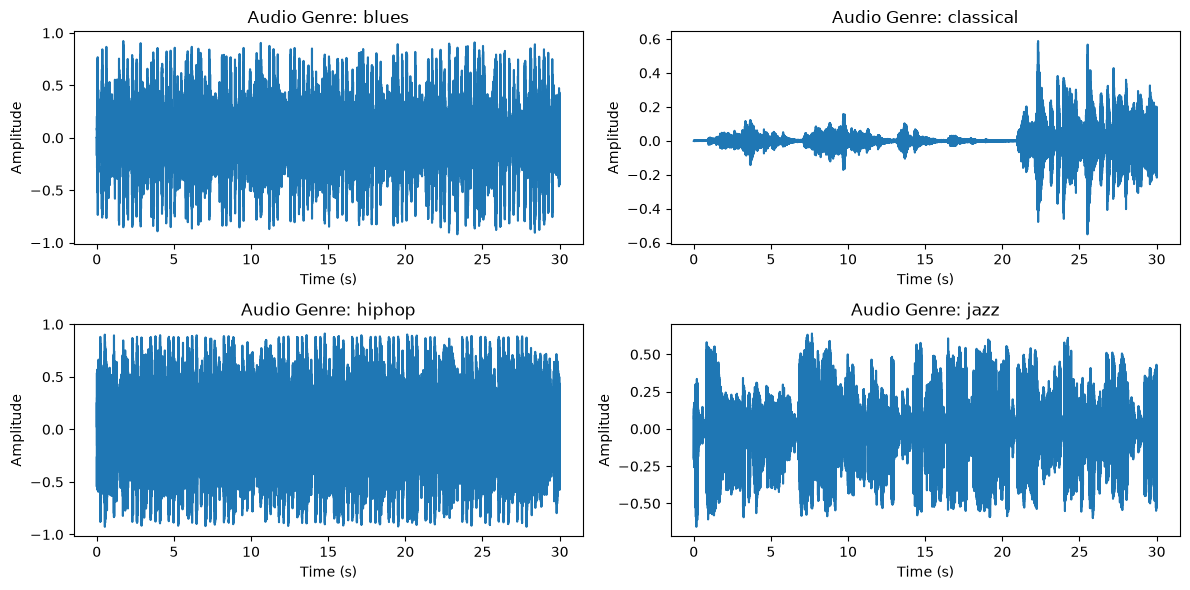

In [3]:
sr = 22050 

audio_samples = gztan.sample(frac=1).head(4)

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 6))

for idx, (_, audio) in enumerate(audio_samples.iterrows()):
    signal = audio["audio"]
    times = np.arange(len(signal)) / sr
    
    curr_ax = ax[idx // 2, idx % 2]
    curr_ax.plot(times, signal)
    
    curr_ax.set(title=f"Audio Genre: {audio['genre']}", xlabel="Time (s)", ylabel="Amplitude")

plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.tight_layout()
plt.show()

## Data Preprocessing

Antes de pasar la múscia al modelo de entrenamiento, en la metodología utilizada ejecutan los siguientes pasos para limpiar y facilitar el proceso de extraer las características importantes de una canción. Esto reduce la complejidad computacional y por ende el tiempo de entrenamiento, al igual que aumenta la capacidad de la red de poder predecir de manera correcta el género musical. Los siguientes pasos convierten el audio crudo en una versión estructurada de la música.

1. Procesada con una Transformada rápida de Fourier (FFT) a 2048 frames
1. Transformación del audio al Mel-Frequency Cepstral Coefficients (MFCC) - a una frecuencia 22050

Base teórica: 
$$ C(x(t)) = F^{-1}[log(F[x(t)])] $$

* x(t) -> representa a la señal / ondas de audio
* t -> tiempo
* F -> Transformación de Fourier - convierte una señal del dominio del tiempo al de frecuencia
* $log(F[x(t)])$ -> Comprime la señal
* $F^{-1}$ -> Extraer las características


In [16]:
SR = 22050
N_FFT = 2048
N_MFCC = 13
DURATION = 30                  # segundos
N_SAMPLES = SR * DURATION      # 661500


def preprocess_audio(audio):
  audio = np.asarray(audio, dtype=np.float32)

  if len(audio) > N_SAMPLES:
    audio = audio[:N_SAMPLES]
  else:
    audio = np.pad(audio, (0, N_SAMPLES - len(audio)))

  mfcc = librosa.feature.mfcc(y=audio, sr=SR, n_fft=N_FFT, n_mfcc=N_MFCC)
  
  return mfcc.astype(np.float32)

gztan["mfcc"] = gztan["audio"].apply(preprocess_audio)

print("Número de canciones: ", len(gztan))
print("Primer MFCC shape", gztan["mfcc"].iloc[0].shape)
print("Unique shgapes: ", gztan["mfcc"].apply(lambda x: x.shape).nunique())
gztan.head()

Número de canciones:  999
Primer MFCC shape (13, 1292)
Unique shgapes:  1


,audio,genre,file,mfcc
0,"[0.0073242188, 0.016601562, 0.0076293945, -0.0...",blues,./music_dataset/gztan/blues\blues.00000.wav,"[[-240.63542, -211.21436, -193.90889, -174.618..."
1,"[0.0034179688, 0.0043029785, 0.001373291, 0.00...",blues,./music_dataset/gztan/blues\blues.00001.wav,"[[-339.1464, -223.89967, -156.06529, -148.9106..."
2,"[0.019012451, 0.047698975, 0.029418945, -0.018...",blues,./music_dataset/gztan/blues\blues.00002.wav,"[[-92.80102, -77.73783, -96.3828, -108.58761, ..."
3,"[-0.013000488, -0.03060913, -0.036071777, -0.0...",blues,./music_dataset/gztan/blues\blues.00003.wav,"[[-220.65663, -201.52414, -213.41223, -220.421..."
4,"[-0.0063171387, -0.009277344, -0.008331299, -0...",blues,./music_dataset/gztan/blues\blues.00004.wav,"[[-281.78323, -180.33914, -155.01845, -173.169..."


Shape:  (13, 1293)


array([[2.40635422e+02, 2.11214355e+02, 1.93908890e+02, ...,
        1.09999146e+02, 8.68144302e+01, 8.40735855e+01],
       [9.96476440e+01, 1.01042831e+02, 1.02243965e+02, ...,
        1.50079346e+02, 1.38948669e+02, 1.38309769e+02],
       [7.40327740e+00, 8.35852718e+00, 1.91543329e+00, ...,
        5.07951355e+01, 3.65361443e+01, 2.81363564e+01],
       ...,
       [2.22809887e+00, 4.09619999e+00, 9.18501377e+00, ...,
        1.21473026e+01, 9.28038788e+00, 1.04724827e+01],
       [3.98046970e+00, 1.07179868e+00, 2.12721896e+00, ...,
        6.25275517e+00, 2.70401955e+00, 4.79276776e-02],
       [9.62528884e-01, 1.38649714e+00, 3.84490371e+00, ...,
        4.95667553e+00, 2.70487642e+00, 6.35826778e+00]],
      shape=(13, 1293), dtype=float32)

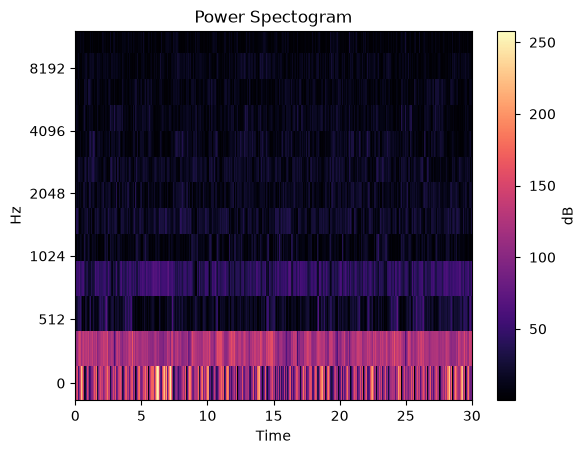

In [5]:
HOP_LENGTH=512
print("Shape: ", gztan['mfcc'][0].shape)

sample = np.abs(gztan['mfcc'].sample(frac=1)[0])
display(sample)

fig, ax = plt.subplots()
img = librosa.display.specshow(sample, x_axis="time", y_axis="mel", sr=SR, hop_length=HOP_LENGTH)
ax.set_title('Power Spectogram')
librosa.display.colorbar_db(img)

In [28]:
from tensorflow.keras.utils import to_categorical

# Stack MFCC en matriz 4D
X = np.stack(gztan["mfcc"].to_numpy())
X = X[..., np.newaxis]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(gztan["genre"])
y = to_categorical(y, num_classes=10)

# Split 70:30
X_train, X_temp, y_train, y_temp = train_test_split(
  X, y,
  test_size=0.30,
  random_state=42,
  stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
  X_temp, y_temp,
  test_size=.5,
  random_state=42,
  stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Val:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Genres:", label_encoder.classes_)

Train: (699, 13, 1292, 1) (699, 10)
Val: (150, 13, 1292, 1) (150, 10)
Test: (150, 13, 1292, 1) (150, 10)
Genres: ['blues' 'classical' 'country' 'disco' 'hiphop' 'jazz' 'metal' 'pop'
 'reggae' 'rock']


In [29]:
mean = X_train.mean(axis=(0,2), keepdims=True)
std = X_train.std(axis=(0,2), keepdims=True)
std = np.maximum(std, 1e-6) # Evitar división entre 0

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

## Data Modeling

### 1. CNN
Para el proyecto aplicaré la arquitectura CNN base, debido a la familiaridad por los temas vistos en clase, y mi inexperiencia con el procesamiento de música y luego una segunda iteración con el modelo modificado de CNN para hacer una comparación directa. <br>
*Posterior a esto, diagnosticaré los resultados de ambos modelos e implementaré una versión que trate de mejorar estos resultados o pueda adaptar música más larga.*

* La red convolucional está hecha para encontrar patrones espaciales y de características en una entrada. 
* Max pooling se utiliza para reducir la información a una dimensión para la capa densa.
* Se suele utilizar softmax para la predicción de categorías. 
- Se puede igual llegar a utilizar *batch normalization* o *dropouts* para reglarizar y estabilizar la época de entrenamiento. 

### 2. CNN modificada

La versión modificada de CNN que menciona el artículo está construida con el modelo de Keras utilizando tres capas de convolución con un kernel (3, 3) y activación ReLU. 
Capas:
1. 256 filtros: Conv2D -> MaxPooing2D: pool-size (3,3) | stride (2,2)
2. 128 filtros: Conv2D -> MaxPooing2D: pool-size (3,3) | stride (2,2)
3. 64 filtros (opcional): Conv2D -> MaxPooing2D: pool-size (3,3) | stride (2,2) -> Batch Normalization -> -> Dense (64, ReLU) -> Dropout (.2) -> Dense (10, softmax) -> Compile (optimizer='ADAM', lr=0.0001)



In [41]:
def compile_model(input_shape, num_clases):
  model = Sequential([
    Input(shape=input_shape),
    
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPool2D((2,2)),
    
    Conv2D(64, (3,3), padding="same", activation="relu"),
    MaxPool2D((2,2)),
    
    Conv2D(128, (3,3), padding="same", activation="relu"),
    GlobalAveragePooling2D(),
    
    Dense(64, activation="relu"),
    Dropout(0.2),
    
    Dense(num_clases, activation="softmax")
  ])
  
  model.compile( 
    optimizer=Adam(), 
    loss=CategoricalCrossentropy(),
    metrics=["accuracy", F1Score(), Precision()]
  )
  
  return model
  
model = compile_model(
  input_shape=X_train.shape[1:],
  num_clases=len(label_encoder.classes_)
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 13, 1292, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 646, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 6, 646, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 3, 323, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 3, 323, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,578 (396.79 KB)

 Trainable params: 101,578 (396.79 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento

In [42]:
callbacks = [
  EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
  ),
  ModelCheckpoint(
    "best_genre_model.keras",
    monitor="val_loss",
    save_best_only=True
  )
]

history = model.fit(
  X_train, y_train, 
  validation_data=(X_val, y_val),
  epochs=50,
  batch_size=16,
  callbacks=callbacks,
  verbose=1
)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - accuracy: 0.1459 - f1_score: 0.1147 - loss: 2.2872 - precision_5: 0.0000e+00 - val_accuracy: 0.1800 - val_f1_score: 0.0684 - val_loss: 2.2155 - val_precision_5: 0.0000e+00
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.2103 - f1_score: 0.1857 - loss: 2.1532 - precision_5: 0.5000 - val_accuracy: 0.3600 - val_f1_score: 0.2783 - val_loss: 1.9879 - val_precision_5: 0.0000e+00
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.3033 - f1_score: 0.2741 - loss: 1.9189 - precision_5: 0.6400 - val_accuracy: 0.3933 - val_f1_score: 0.3186 - val_loss: 1.7340 - val_precision_5: 1.0000
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.3834 - f1_score: 0.3493 - loss: 1.7410 - precision_5: 0.7679 - val_accuracy: 0.4133 - val_f1_score: 0.3661 - val_loss: 1.5606 - val_precision_5: 0.8421
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.3977 - f1_score: 0.3688 - loss: 1.6466 - precision

## Evaluation

Test loss: 0.9465
Test accuracy: 0.0000
Test f1: [0.64       0.96774185 0.4848484  0.6666666  0.6896552  0.7586206
 0.8387096  0.7222222  0.6666666  0.49999994]
Test precision: 0.7667
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
              precision    recall  f1-score   support

       blues       0.80      0.53      0.64        15
   classical       0.94      1.00      0.97        15
     country       0.44      0.53      0.48        15
       disco       0.75      0.60      0.67        15
      hiphop       0.71      0.67      0.69        15
        jazz       0.79      0.73      0.76        15
       metal       0.81      0.87      0.84        15
         pop       0.62      0.87      0.72        15
      reggae       0.75      0.60      0.67        15
        rock       0.47      0.53      0.50        15

    accuracy                           0.69       150
   macro avg       0.71      0.69      0.69       150
weighted avg       0.71      0.69      0.69       150



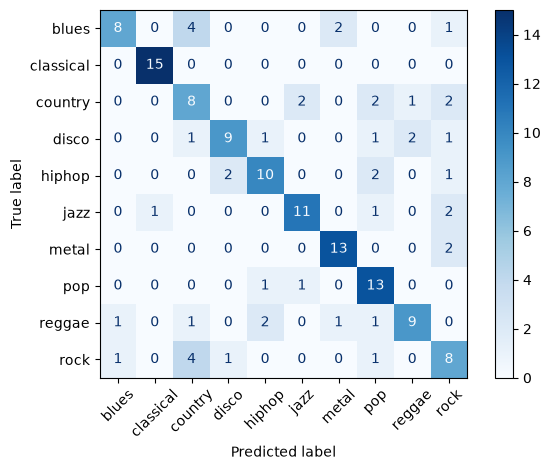

In [40]:
loss, test_accuracy, f1_score, precision = model.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("Test f1:", f1_score)
print(f"Test precision: {precision:.4f}")

y_pred = np.argmax(model.predict(X_test), axis=1)
y_test_classes = np.argmax(y_test, axis=1)

print(
    classification_report(
        y_test_classes,  # Usa la versión 1D de y_test
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0,
    )
)

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test_classes,  # Usa la versión 1D de y_test
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
)

plt.tight_layout()
plt.show()

# Referencias: 

Ahmed, M., Rozario, U., Kabir, M. M., Aung, Z., Shin, J., & Mridha, M. F. (2024). Musical genre classification using advanced audio analysis and deep learning techniques. IEEE Open Journal of the Computer Society, 5, 457–467. https://doi.org/10.1109/OJCS.2024.3431229 

TensorFlow. (s. f.). GTZAN: A dataset for music genre classification. TensorFlow Datasets. Recuperado el 18 de octubre de 2026, de https://www.tensorflow.org/datasets/catalog/gtzan 

Lewtun. (s. f.). Music genres dataset [Conjunto de datos]. Hugging Face. Recuperado el 18 de octubre de 2026, de https://huggingface.co/datasets/lewtun/music_genres 

Patel, S. J. (2026). Sunnify Spotify Downloader (Versión 2.5.0) [Software de computación]. GitHub. https://github.com/sunnypatell/sunnify-spotify-downloader

In [ ]:
@misc{tzanetakis2002gtzan,
  title={GTZAN Genre Collection},
  author={George Tzanetakis and Perry Cook},
  year={2002},
  url={http://marsyasweb.appspot.com/download/data_sets/}
}